<a href="https://colab.research.google.com/github/muhammadhanzla7878987-dot/Python/blob/main/Copy_of_Facial_Emotion_Recognition_using_CNN_Model_(FER_2013).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving archive (3).zip to archive (3).zip


**Explanation:**
This cell opens a file selection window. Click Choose Files and select your **dataset file** from your computer.

In [ ]:
import os
print("Uploaded files:")
for file in os.listdir("/content"):
    print(file)

Uploaded files:
.config
archive (3).zip
sample_data


**Explanation:**
This cell checks whether the dataset ZIP file was successfully uploaded to Google Colab.

In [ ]:
import zipfile
import os
zip_file = "/content/archive (3).zip"
extract_folder = "/content/emotion_dataset"
with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(extract_folder)
print("Dataset extracted successfully!")

Dataset extracted successfully!


**Explanation:**
The ZIP file contains our dataset. This cell extracts all images into the emotion_dataset folder.

In [ ]:
print("Files and folders inside dataset:")
for item in os.listdir("/content/emotion_dataset"):
    print(item)

Files and folders inside dataset:
test
train


**Explanation:**
This cell checks what was extracted from the ZIP file.

In [ ]:
import tensorflow as tf
print("TensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))

TensorFlow Version: 2.20.0
GPU Available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Explanation:**
This cell checks whether Google Colab has a GPU.Because GPU helps us train the CNN model faster.

In [ ]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Sequential
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
print("Libraries imported successfully!")

Libraries imported successfully!


**Explanation:**
This cell imports all required libraries.

**NumPy →** numerical operations

**Pandas →** data handling

**Matplotlib/Seaborn** → graphs

**TensorFlow/Keras →** CNN model
Scikit-learn → evaluation

In [ ]:
train_path = "/content/emotion_dataset/train"
test_path = "/content/emotion_dataset/test"
classes = sorted(os.listdir(train_path))
print("Emotion Classes:")
for i, emotion in enumerate(classes):
    print(i, "=", emotion)

Emotion Classes:
0 = angry
1 = disgust
2 = fear
3 = happy
4 = neutral
5 = sad
6 = surprise


**Explaination:**
This cell finds all emotion classes automatically from the training folder.

There are **7 emotion classes**.

In [ ]:
train_counts = {}
for emotion in classes:
    folder = os.path.join(train_path, emotion)
    train_counts[emotion] = len(os.listdir(folder))
train_counts

{'angry': 3995,
 'disgust': 436,
 'fear': 4097,
 'happy': 7215,
 'neutral': 4965,
 'sad': 4830,
 'surprise': 3171}

**Explanation:**
This cell counts how many images are available for each emotion in the training dataset.

This is important because we need to check whether the dataset is balanced or imbalanced.

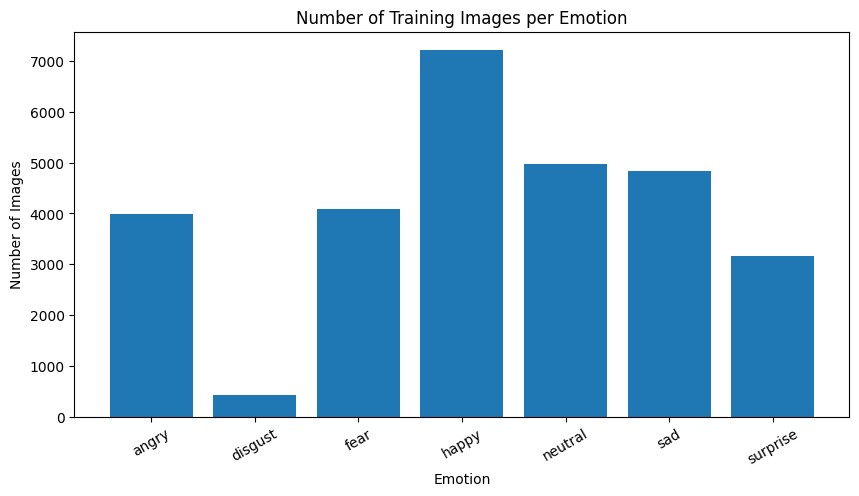

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(train_counts.keys(), train_counts.values())
plt.title("Number of Training Images per Emotion")
plt.xlabel("Emotion")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

**Explanation:**
This graph shows the number of images available for every emotion.

This is called **Class Distribution**.

It helps us understand our dataset before training.

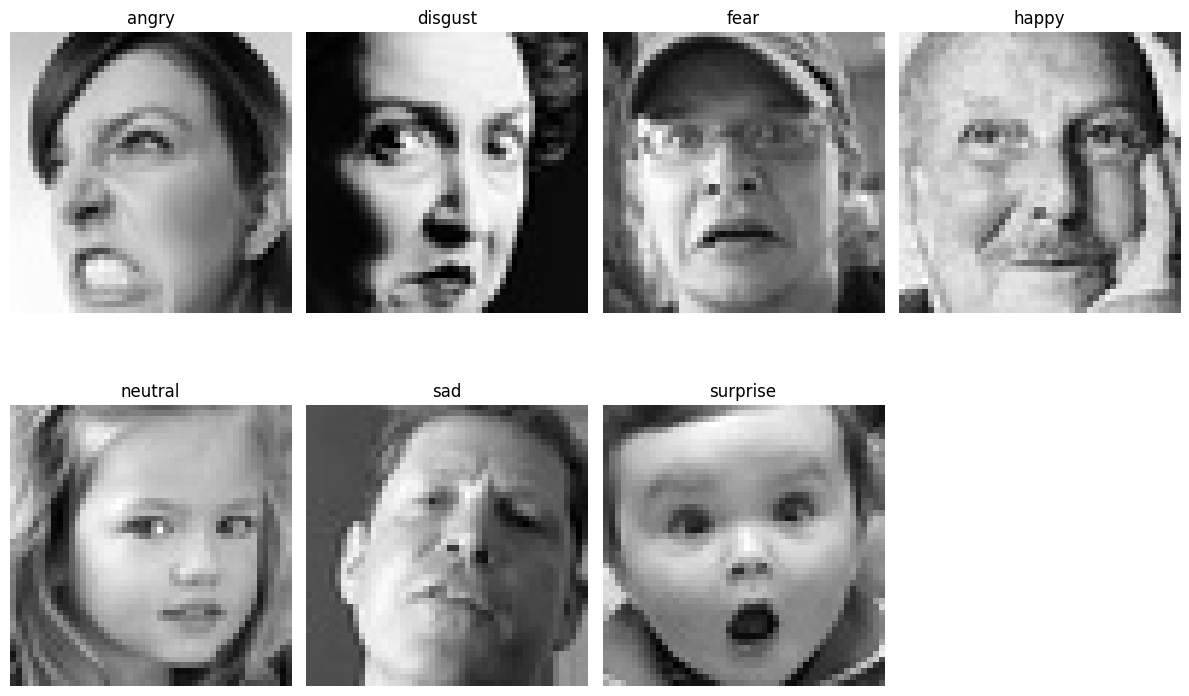

In [ ]:
plt.figure(figsize=(12, 8))
for i, emotion in enumerate(classes):
    folder = os.path.join(train_path, emotion)
    image_name = os.listdir(folder)[0]
    image_path = os.path.join(folder, image_name)
    image = plt.imread(image_path)
    plt.subplot(2, 4, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(emotion)
    plt.axis("off")
plt.tight_layout()
plt.show()

**Explanation:**
This cell displays one example image from every emotion.

It helps us visually understand what our model needs to classify.

In [ ]:
from PIL import Image
sample_image_path = os.path.join(
    train_path,
    classes[0],
    os.listdir(os.path.join(train_path, classes[0]))[0]
)
image = Image.open(sample_image_path)
print("Image Size:", image.size)
print("Image Mode:", image.mode)

Image Size: (48, 48)
Image Mode: L


**Explanation:**
Our images are small 48×48 grayscale images.

**Grayscale** means the image has only one color channel instead of RGB's three channels.

In [ ]:
IMG_SIZE = (48, 48)
BATCH_SIZE = 64
SEED = 42
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    validation_split=0.20,
    subset="training",
    seed=SEED
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    validation_split=0.20,
    subset="validation",
    seed=SEED
)
print("Training and validation datasets created.")

Found 28709 files belonging to 7 classes.
Using 22968 files for training.
Found 28709 files belonging to 7 classes.
Using 5741 files for validation.
Training and validation datasets created.


**Explanation:**
We divide our original training data into:

**80% Training**
and
**20% Validation**

**Validation data** is used during training to check how well the model performs on unseen images.

In [ ]:
test_ds = tf.keras.utils.image_dataset_from_directory(
    test_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="grayscale",
    shuffle=False
)
print("Test dataset created.")

Found 7178 files belonging to 7 classes.
Test dataset created.


**Explanation:**
The test dataset is kept separate.

The model does not train on test images.

We use test data at the end to measure final performance.

In [ ]:
for images, labels in train_ds.take(1):
    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

Image Batch Shape: (64, 48, 48, 1)
Label Batch Shape: (64,)


**Explanation:**
The image shape means:

**64  → **number of images

**48  →** height

**48  →** width

**1   →** grayscale channel

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.cache().prefetch(buffer_size=AUTOTUNE)
print("Dataset optimization completed.")

Dataset optimization completed.


**Explanation:**
***cache()***  and **prefetch()** make data loading faster during model training.

This is useful when working with a large image dataset.

In [ ]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.10)
])
print("Data augmentation created.")

Data augmentation created.


**Explanation:**
Data augmentation creates slightly different versions of training images.

**For example:**

**1.Flip**

**2.Rotate**

**3.Zoom**

This helps the model generalize better and can reduce overfitting.

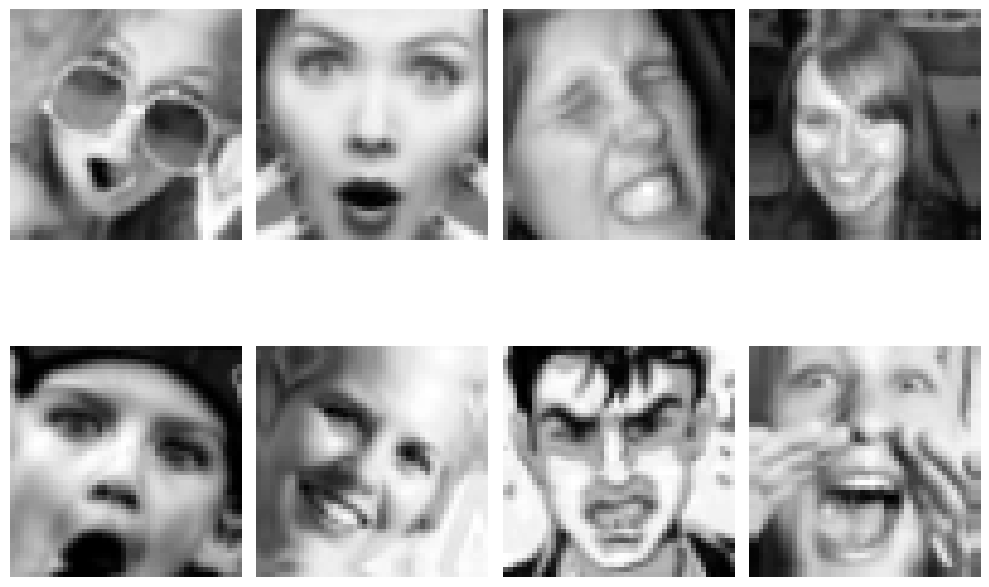

In [ ]:
for images, labels in train_ds.take(1):
    plt.figure(figsize=(10, 8))
    for i in range(8):
        augmented_image = data_augmentation(images[i:i+1])
        plt.subplot(2, 4, i + 1)
        plt.imshow(augmented_image[0], cmap="gray")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
    break

**Exlanation:**
This cell shows examples after data augmentation.

The images are changed slightly while keeping the same emotion.

In [ ]:
model = Sequential([
    layers.Input(shape=(48, 48, 1)),
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.40),
    layers.Dense(7, activation="softmax")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       589,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 684,423 (2.61 MB)

 Trainable params: 683,975 (2.61 MB)

 Non-trainable params: 448 (1.75 KB)

**Explanation:**
This is a Convolutional Neural Network (CNN).

Main layers:

**Conv2D →** extracts image features

**BatchNormalization →** stabilizes training

**MaxPooling →** reduces image size

**Dropout →** reduces overfitting

**Flatten →** converts features into

one-dimensional data

**Dense →** performs classification

**Softmax →** gives probabilities for 7 emotions
    

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully.")

Model compiled successfully.


**Explanation:**
Here we configure the model.

**Adam** is the optimizer.

**Sparse categorical crossentropy** is the loss function because we have multiple classes.

**Accuracy** measures  correct predictions.

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)
reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)
print("Callbacks created.")

Callbacks created.


**Explanation:**
These callbacks improve training.

**EarlyStopping** stops training when validation performance stops improving.

**ReduceLROnPlateau** reduces the learning rate when learning becomes slow.

This helps prevent unnecessary training and overfitting.

In [ ]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print("\nFinal Test Loss:", test_loss)
print("Final Test Accuracy:", test_accuracy)
print("Final Test Accuracy (%):", test_accuracy * 100)

113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.1137 - loss: 1.9514

Final Test Loss: 1.9514052867889404
Final Test Accuracy: 0.11368069052696228
Final Test Accuracy (%): 11.368069052696228


**Explanation:**
This is our final evaluation on completely unseen test images.

In [ ]:
y_true = []
y_pred = []
for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)
    predicted_labels = np.argmax(predictions, axis=1)
    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)
y_true = np.array(y_true)
y_pred = np.array(y_pred)
print("Predictions generated successfully.")

Predictions generated successfully.


**Explanation:**
This cell gets predictions for all test images.

**y_true** contains actual emotions.

**y_pred** contains model-predicted emotions.

In [ ]:
accuracy = accuracy_score(y_true, y_pred)
print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

Test Accuracy: 0.11368069100027862
Test Accuracy (%): 11.368069100027862


**Explanation:**
Here we calculate test accuracy using Scikit-learn.

This gives another way to verify our model's performance.

In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        target_names=classes
    )
)

              precision    recall  f1-score   support

       angry       0.13      0.78      0.23       958
     disgust       0.01      0.17      0.03       111
        fear       0.00      0.00      0.00      1024
       happy       0.23      0.03      0.05      1774
     neutral       0.00      0.00      0.00      1233
         sad       0.00      0.00      0.00      1247
    surprise       0.00      0.00      0.00       831

    accuracy                           0.11      7178
   macro avg       0.05      0.14      0.04      7178
weighted avg       0.08      0.11      0.04      7178



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


**Explanation:**
This gives important ML evaluation metrics:

**Precision**

**Recall**

**F1-score**

**Support**

This is important for your project because accuracy alone does not show performance for every emotion.

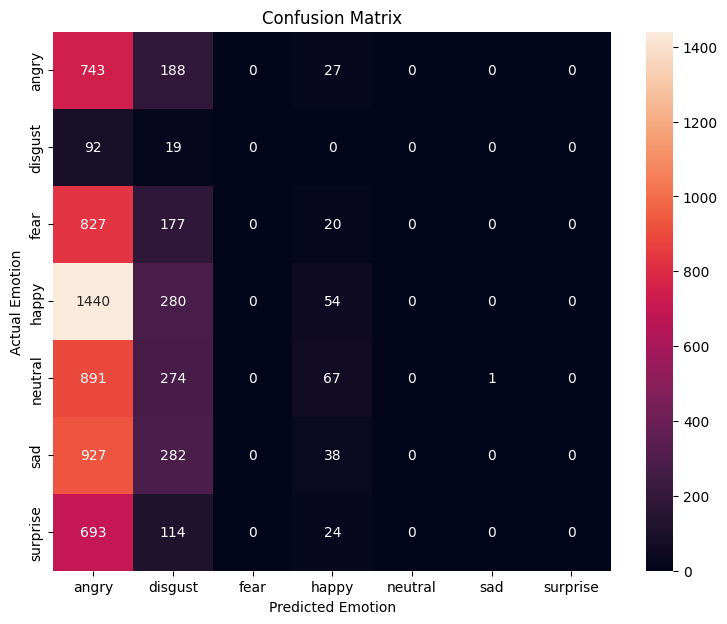

In [ ]:
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=classes,
    yticklabels=classes
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.show()

**Explanation:**
A confusion matrix shows where the model makes correct and incorrect predictions.

**For example:**

Actual Happy → Predicted Happy

is a correct prediction.

**But:**

Actual Sad → Predicted Fear

is an incorrect prediction.

In [ ]:
class_accuracy = cm.diagonal() / cm.sum(axis=1)
for emotion, acc in zip(classes, class_accuracy):
    print(f"{emotion}: {acc * 100:.2f}%")

angry: 77.56%
disgust: 17.12%
fear: 0.00%
happy: 3.04%
neutral: 0.00%
sad: 0.00%
surprise: 0.00%


**Explanation:**
This shows accuracy separately for each emotion.

**For example:**

happy: 78.20%

sad: 61.50%

angry: 65.30%

This helps us understand which emotions are easier or harder for the model.

In [ ]:
model.save("/content/facial_emotion_model.keras")
print("Model saved successfully!")

Model saved successfully!


**Explanation:**
This saves our trained CNN model.

We can use this model later without training it again.

**Now comes the most important final demonstration.**

Apload any new image.

In [ ]:
from google.colab import files
uploaded_image = files.upload()
image_name = list(uploaded_image.keys())[0]
print("Uploaded Image:", image_name)

Saving images (2).jpg to images (2).jpg
Uploaded Image: images (2).jpg


**Explanation:**
This allows you to upload a completely any new face image.

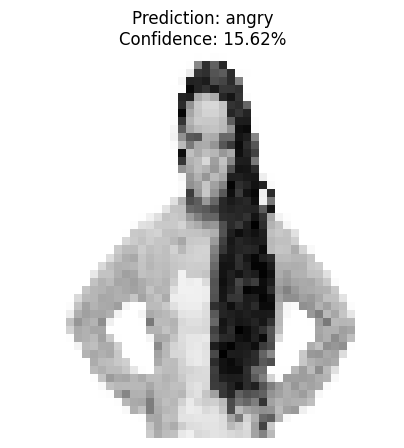

Predicted Emotion: angry
Confidence: 15.62%


In [ ]:
from tensorflow.keras.utils import load_img, img_to_array
image = load_img(
    image_name,
    target_size=(48, 48),
    color_mode="grayscale"
)
image_array = img_to_array(image)
image_array = np.expand_dims(image_array, axis=0)
prediction = model.predict(image_array, verbose=0)
predicted_index = np.argmax(prediction[0])
predicted_emotion = classes[predicted_index]
confidence = prediction[0][predicted_index] * 100
plt.figure(figsize=(5, 5))
plt.imshow(image_array[0].squeeze(), cmap="gray")
plt.title(
    f"Prediction: {predicted_emotion}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.axis("off")
plt.show()
print("Predicted Emotion:", predicted_emotion)
print("Confidence:", f"{confidence:.2f}%")

**Explanation:**
This cell takes a new image and predicts its emotion and also tell confidence.

In [ ]:
probabilities = prediction[0] * 100
for emotion, probability in zip(classes, probabilities):
    print(f"{emotion}: {probability:.2f}%")

angry: 15.62%
disgust: 15.27%
fear: 12.86%
happy: 15.10%
neutral: 13.93%
sad: 14.07%
surprise: 13.16%


**Explanation:**
The **CNN** gives a probability for every emotion.

The emotion with the highest probability becomes the final prediction.

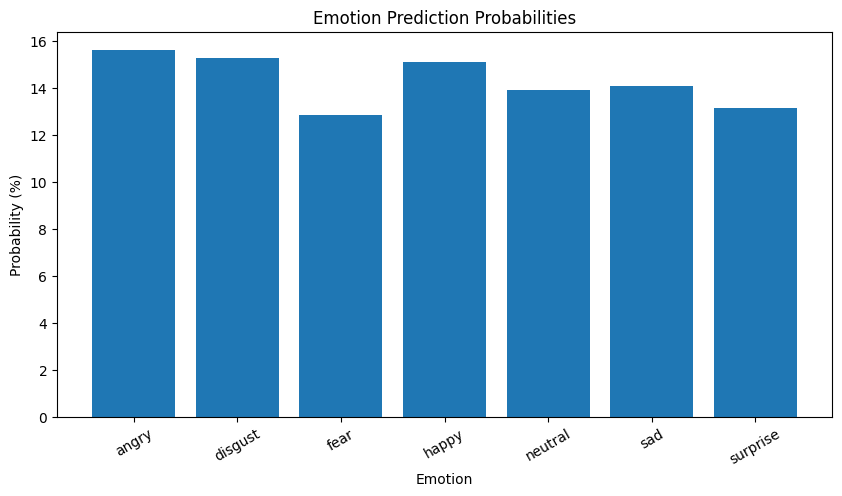

In [ ]:
plt.figure(figsize=(10, 5))
plt.bar(classes, probabilities)
plt.title("Emotion Prediction Probabilities")
plt.xlabel("Emotion")
plt.ylabel("Probability (%)")
plt.xticks(rotation=30)
plt.show()

**Explanation:**
This graph shows how confident the model is about every emotion.

This makes the final prediction easier to understand visually.

In [ ]:
from google.colab import files
multiple_images = files.upload()
for image_name in multiple_images.keys():
    image = load_img(
        image_name,
        target_size=(48, 48),
        color_mode="grayscale"
    )
    image_array = img_to_array(image)
    image_array = np.expand_dims(image_array, axis=0)
    prediction = model.predict(image_array, verbose=0)
    predicted_index = np.argmax(prediction[0])
    predicted_emotion = classes[predicted_index]
    confidence = prediction[0][predicted_index] * 100
    print("--------------------------------")
    print("Image:", image_name)
    print("Predicted Emotion:", predicted_emotion)
    print("Confidence:", f"{confidence:.2f}%")

Saving gettyimages-2152678893-612x612.jpg to gettyimages-2152678893-612x612.jpg
--------------------------------
Image: gettyimages-2152678893-612x612.jpg
Predicted Emotion: angry
Confidence: 15.29%


**Explanation:**
This cell allows us to upload multiple images at once.

The model predicts the emotion of every image separately.

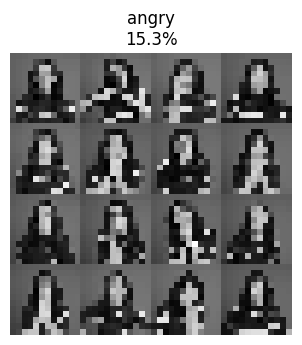

In [ ]:
image_names = list(multiple_images.keys())
plt.figure(figsize=(15, 10))
for i, image_name in enumerate(image_names):
    image = load_img(
        image_name,
        target_size=(48, 48),
        color_mode="grayscale"
    )
    image_array = img_to_array(image)
    input_image = np.expand_dims(image_array, axis=0)
    prediction = model.predict(input_image, verbose=0)
    predicted_index = np.argmax(prediction[0])
    predicted_emotion = classes[predicted_index]
    confidence = prediction[0][predicted_index] * 100
    plt.subplot(2, 5, i + 1)
    plt.imshow(image_array.squeeze(), cmap="gray")
    plt.title(
        f"{predicted_emotion}\n{confidence:.1f}%"
    )
    plt.axis("off")
plt.tight_layout()
plt.show()

**Explanation:**
This displays multiple test images together with their predicted emotions and confidence.

In [ ]:
print("========== FINAL PROJECT RESULTS ==========")
print("Project: Facial Emotion Recognition")
print("Number of Classes:", len(classes))
print("Classes:", classes)
print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("\nModel: Convolutional Neural Network (CNN)")
print("Image Size: 48 x 48")
print("Color Mode: Grayscale")
print("\nProject completed successfully!")

========== FINAL PROJECT RESULTS ==========
Project: Facial Emotion Recognition
Number of Classes: 7
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Test Accuracy: 11.37%
Test Loss: 1.9514

Model: Convolutional Neural Network (CNN)
Image Size: 48 x 48
Color Mode: Grayscale

Project completed successfully!


**Explanation:**
This cell gives a final summary of our project.

**It displays:**

**1.** Project name

**2.** Number of classes

**3.** Emotions

**4.** Test accuracy

**5.** Test loss

**6.** CNN information